In [5]:
#Laplace Equation (delta^2 V = 0)

#Finite Difference Method (FDM)

#Calculation of electric potential between different charged boundaries

#Gauss-Seidel Iteration Method

import numpy as np
import matplotlib.pyplot as plt

#define grid
Lx = 1
Ly = 1
Nx = 51
Ny = 51

dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)

X, Y = np.meshgrid(x, y)

In [7]:
#initialize potential

V = np.zeros((Ny, Nx))

V_top = 100
V_bottom = 0
V_left = 50
V_right = 0

V[-1, :] = V_top
V[0, :] = V_bottom
V[:, 0] = V_left
V[:, -1] = V_right

In [10]:
#Gauss-Seidel Iteration

tol = 1e-6
max_itr = 20000

for itr in range(max_itr):
    max_err = 0
    for j in range(1, Ny - 1):
        for i in range(1, Nx - 1):
            old_value = V[j, i]
            V[j, i] = ( (V[j, i+1] + V[j, i-1]) / dx**2 + (V[j+1, i] + V[j-1, i]) / dy**2 ) / ( 2 / dx**2 + 2 / dy**2)
            err = abs(V[j, i] - old_value)
            max_err = max(max_err, err)
    if(max_err < tol):
        break

print('Iterations:', itr + 1)
print('Max Error:', max_err)

Iterations: 1
Max Error: 9.882575469077892e-07


In [16]:
print("Potential Distribution (V):\n", np.round(V, 2))
print("Central Potential:", V[Ny//2, Nx//2], "V")

Potential Distribution (V):
 [[5.000e+01 0.000e+00 0.000e+00 ... 0.000e+00 0.000e+00 0.000e+00]
 [5.000e+01 2.502e+01 1.516e+01 ... 1.300e-01 7.000e-02 0.000e+00]
 [5.000e+01 3.493e+01 2.509e+01 ... 2.600e-01 1.300e-01 0.000e+00]
 ...
 [5.000e+01 6.499e+01 7.474e+01 ... 4.991e+01 3.019e+01 0.000e+00]
 [5.000e+01 7.493e+01 8.475e+01 ... 6.972e+01 4.998e+01 0.000e+00]
 [5.000e+01 1.000e+02 1.000e+02 ... 1.000e+02 1.000e+02 0.000e+00]]
Central Potential: 37.499750330017264 V


In [20]:
#Electric Field
dV_dy, dV_dx = np.gradient(V, dy, dx)

Ex = - dV_dx
Ey = - dV_dy

E = np.sqrt(Ex**2 + Ey**2)

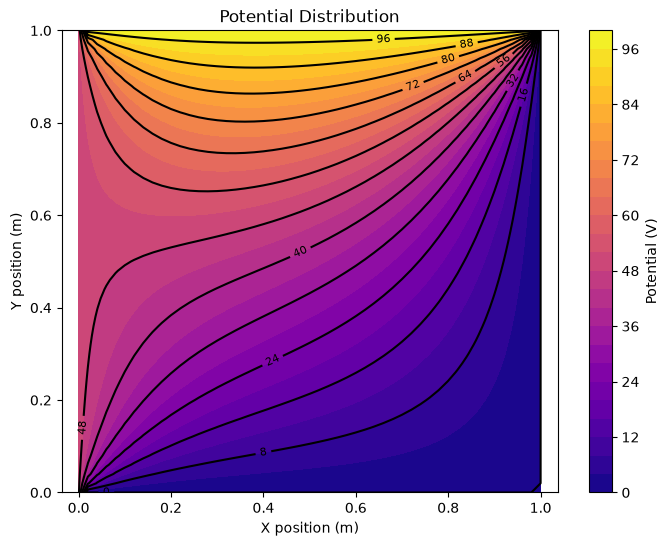

In [22]:
#potential distribution plot

plt.figure(figsize=(8, 6))

contour = plt.contourf(X, Y, V, levels=30, cmap='plasma')

plt.colorbar(contour, label='Potential (V)')

lines = plt.contour(X, Y, V, levels=15, colors='black')

plt.clabel(lines, inline=True, fontsize=8)

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')

plt.title('Potential Distribution')

plt.axis('equal')
plt.show()

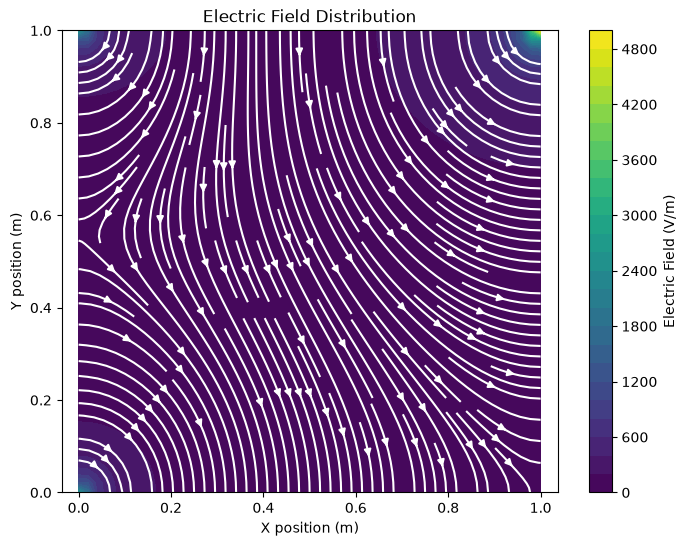

In [26]:
#electric field plot

plt.figure(figsize=(8, 6))

contour = plt.contourf(X, Y, E, levels=30, cmap='viridis')

plt.colorbar(contour, label='Electric Field (V/m)')

plt.streamplot(X, Y, Ex, Ey, color='white', density=1.5)

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')

plt.title('Electric Field Distribution')

plt.axis('equal')
plt.show()

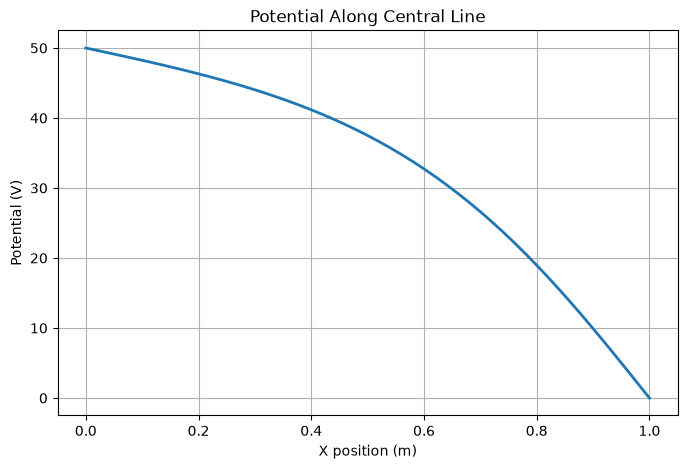

In [27]:
#potential along central line

plt.figure(figsize=(8,5))
plt.plot(x, V[Ny//2, :], linewidth=2)

plt.xlabel('X position (m)')
plt.ylabel('Potential (V)')

plt.title('Potential Along Central Line')
plt.grid()
plt.show()